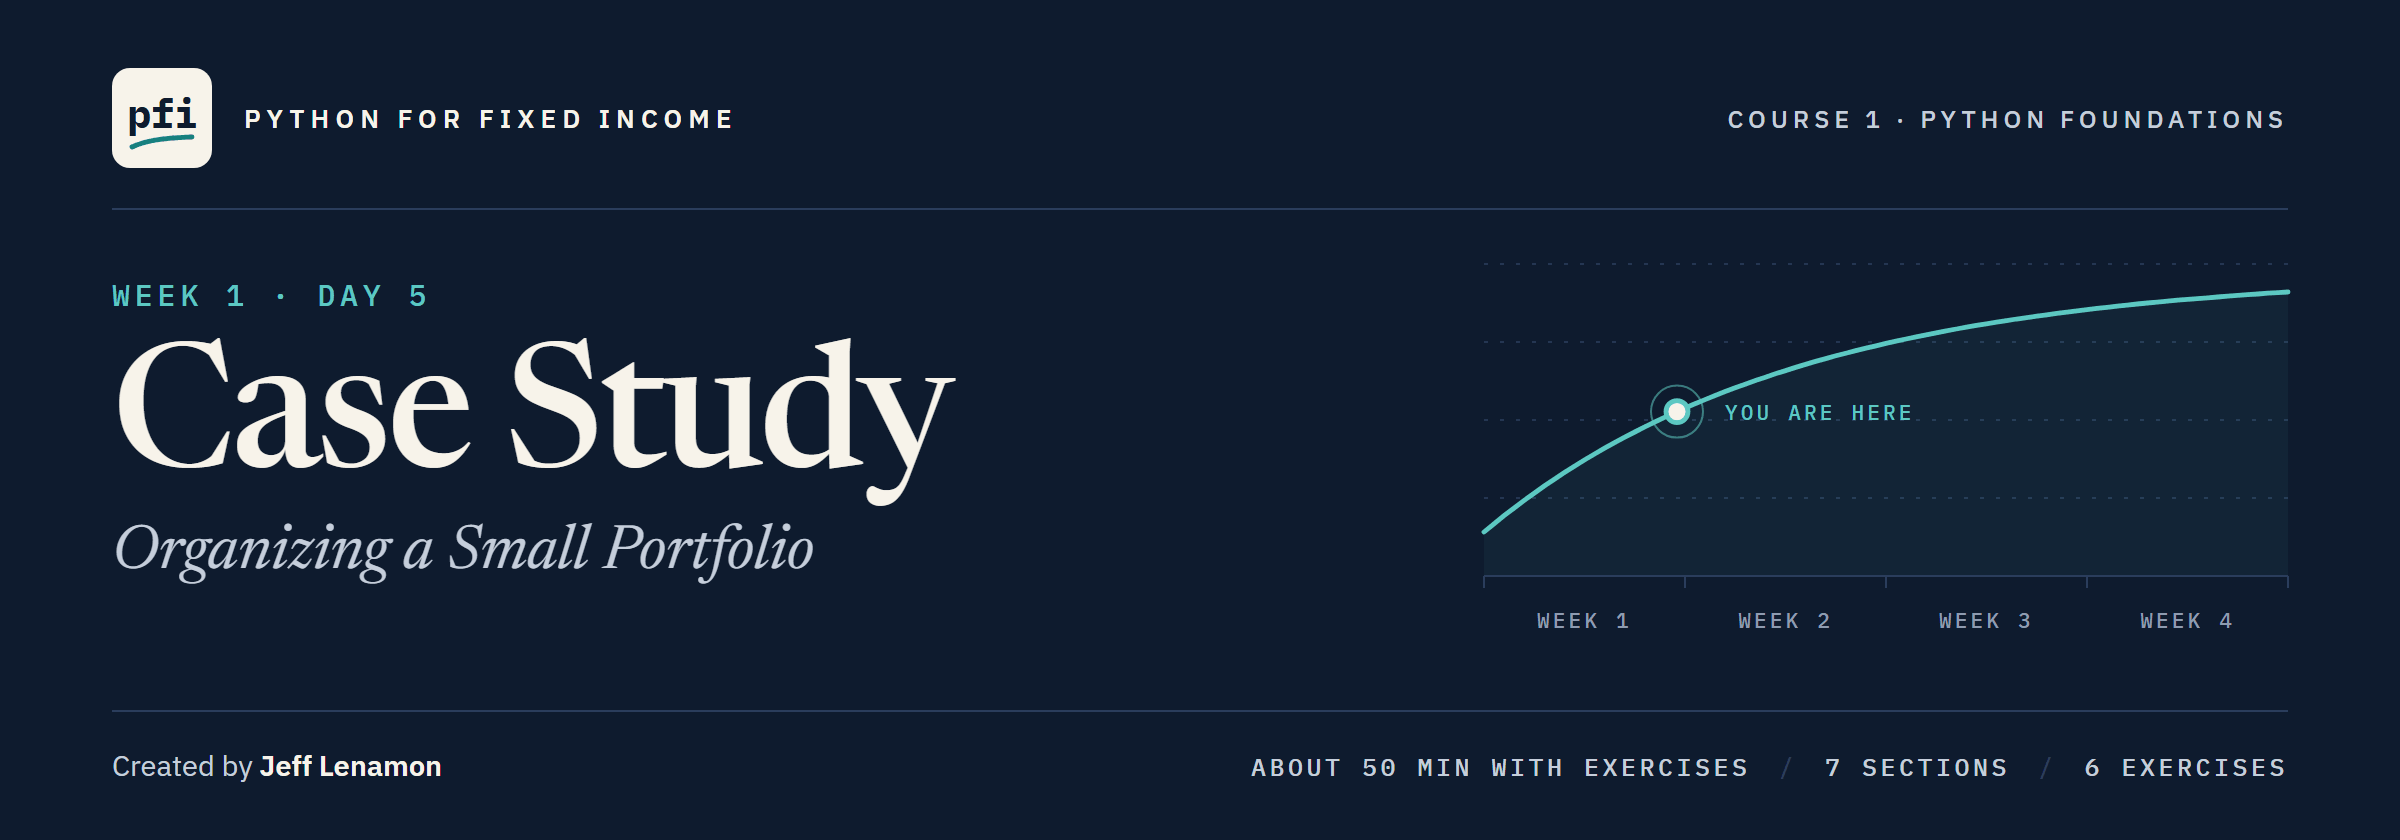

# Case Study: Organizing a Small Portfolio

Week 1, Day 5. One job from start to finish, using everything from the week.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day5/05_case_study_a_small_portfolio.ipynb)

## Problem Definition

### Context

The desk lead's seventh note:

> Another team has handed us OSTV and VYRH. Their email lists all six of our bonds, typed into the body: no file, no system record. Put the book in order before anyone analyzes it, make sure it ties to the email's 4,400,000 face, and hand it on as a file.

The week's four bonds, 3,000,000 face, plus two new ones, 1,400,000.

### Objective

You are the desk's analyst.
Store the six bonds so that it is easy to:

* look up everything about one bond,
* update a bond when its rating or price changes,
* answer simple questions about the book, and
* hand it on as a table built for analysis, and as a file.

### The Data

The email's six bonds, as a sheet pasted at A1; the issuers are invented.

<table align="left">
<tr><th align="left">A: Ticker</th><th align="left">B: Issuer</th><th align="left">C: Sector</th><th align="left">D: Rating</th><th align="left">E: Score</th><th align="left">F: Coupon (%)</th><th align="left">G: Price</th><th align="left">H: Face held</th></tr>
<tr><td align="left">QVNE</td><td align="left">Quorvane Energy</td><td align="left">Energy</td><td align="left">BBB</td><td align="left">9</td><td align="left">5.25</td><td align="left">98.50</td><td align="left">1,500,000</td></tr>
<tr><td align="left">DNMR</td><td align="left">Dunmarrow Rail</td><td align="left">Transportation</td><td align="left">BB+</td><td align="left">11</td><td align="left">6.125</td><td align="left">103.25</td><td align="left">500,000</td></tr>
<tr><td align="left">PLWK</td><td align="left">Pellwick Paper</td><td align="left">Materials</td><td align="left">A-</td><td align="left">7</td><td align="left">4.75</td><td align="left">95.00</td><td align="left">750,000</td></tr>
<tr><td align="left">HLVF</td><td align="left">Halvering Foods</td><td align="left">Consumer</td><td align="left">B+</td><td align="left">14</td><td align="left">7.50</td><td align="left">101.00</td><td align="left">250,000</td></tr>
<tr><td align="left">OSTV</td><td align="left">Ostrevale Telecom</td><td align="left">Telecom</td><td align="left">BBB-</td><td align="left">10</td><td align="left">5.75</td><td align="left">99.00</td><td align="left">1,000,000</td></tr>
<tr><td align="left">VYRH</td><td align="left">Veyrholt Health</td><td align="left">Health Care</td><td align="left">BB</td><td align="left">12</td><td align="left">6.75</td><td align="left">102.50</td><td align="left">400,000</td></tr>
</table>
<br clear="left">

The score is Part 2's: AAA is 1, one more for each notch lower; 10 or lower is investment grade, 11 or higher high yield.

### How We Will Work

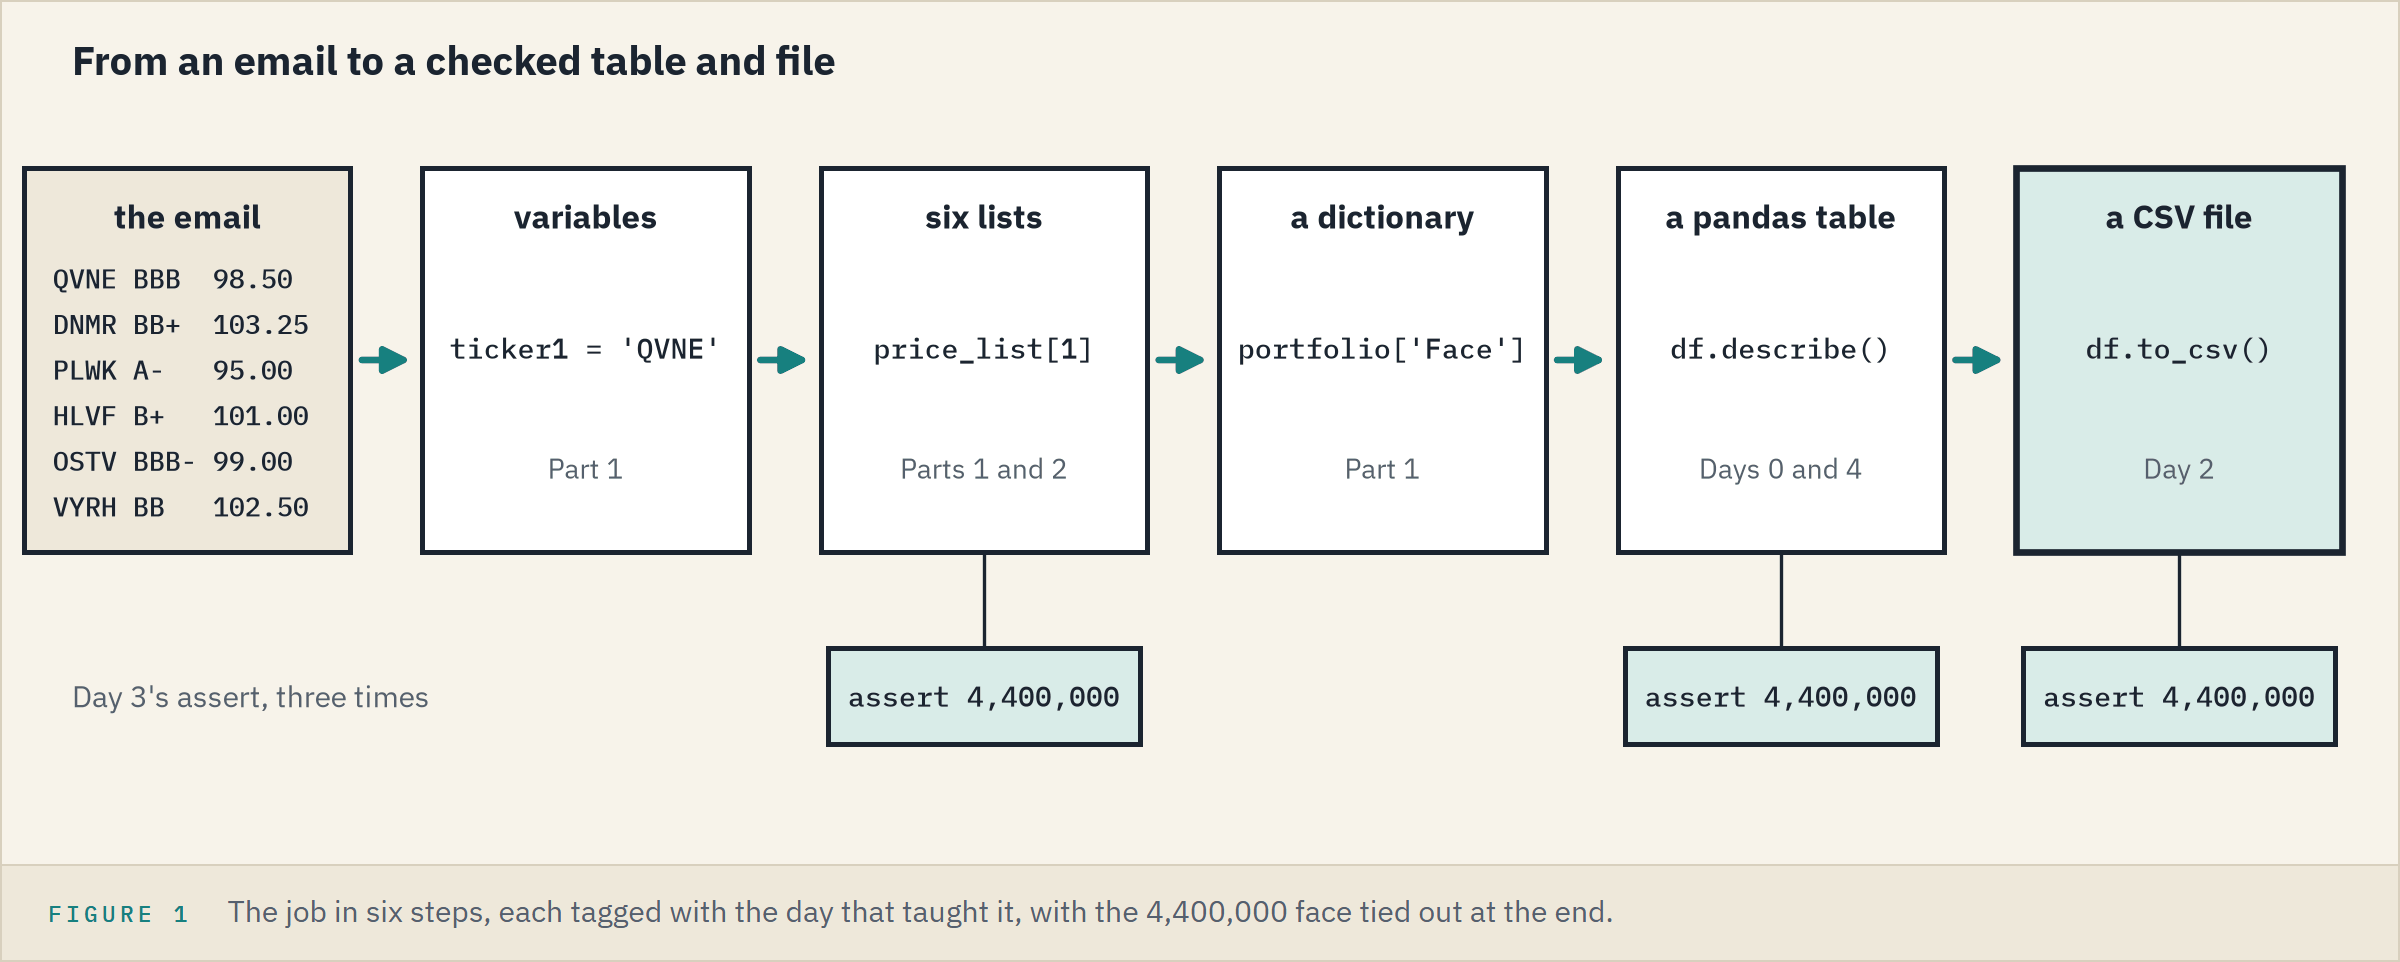

We start simple and move on each time the current way gets awkward: that is how real code grows.

**Start with the simplest store there is.**

## Your Route Through Day 5

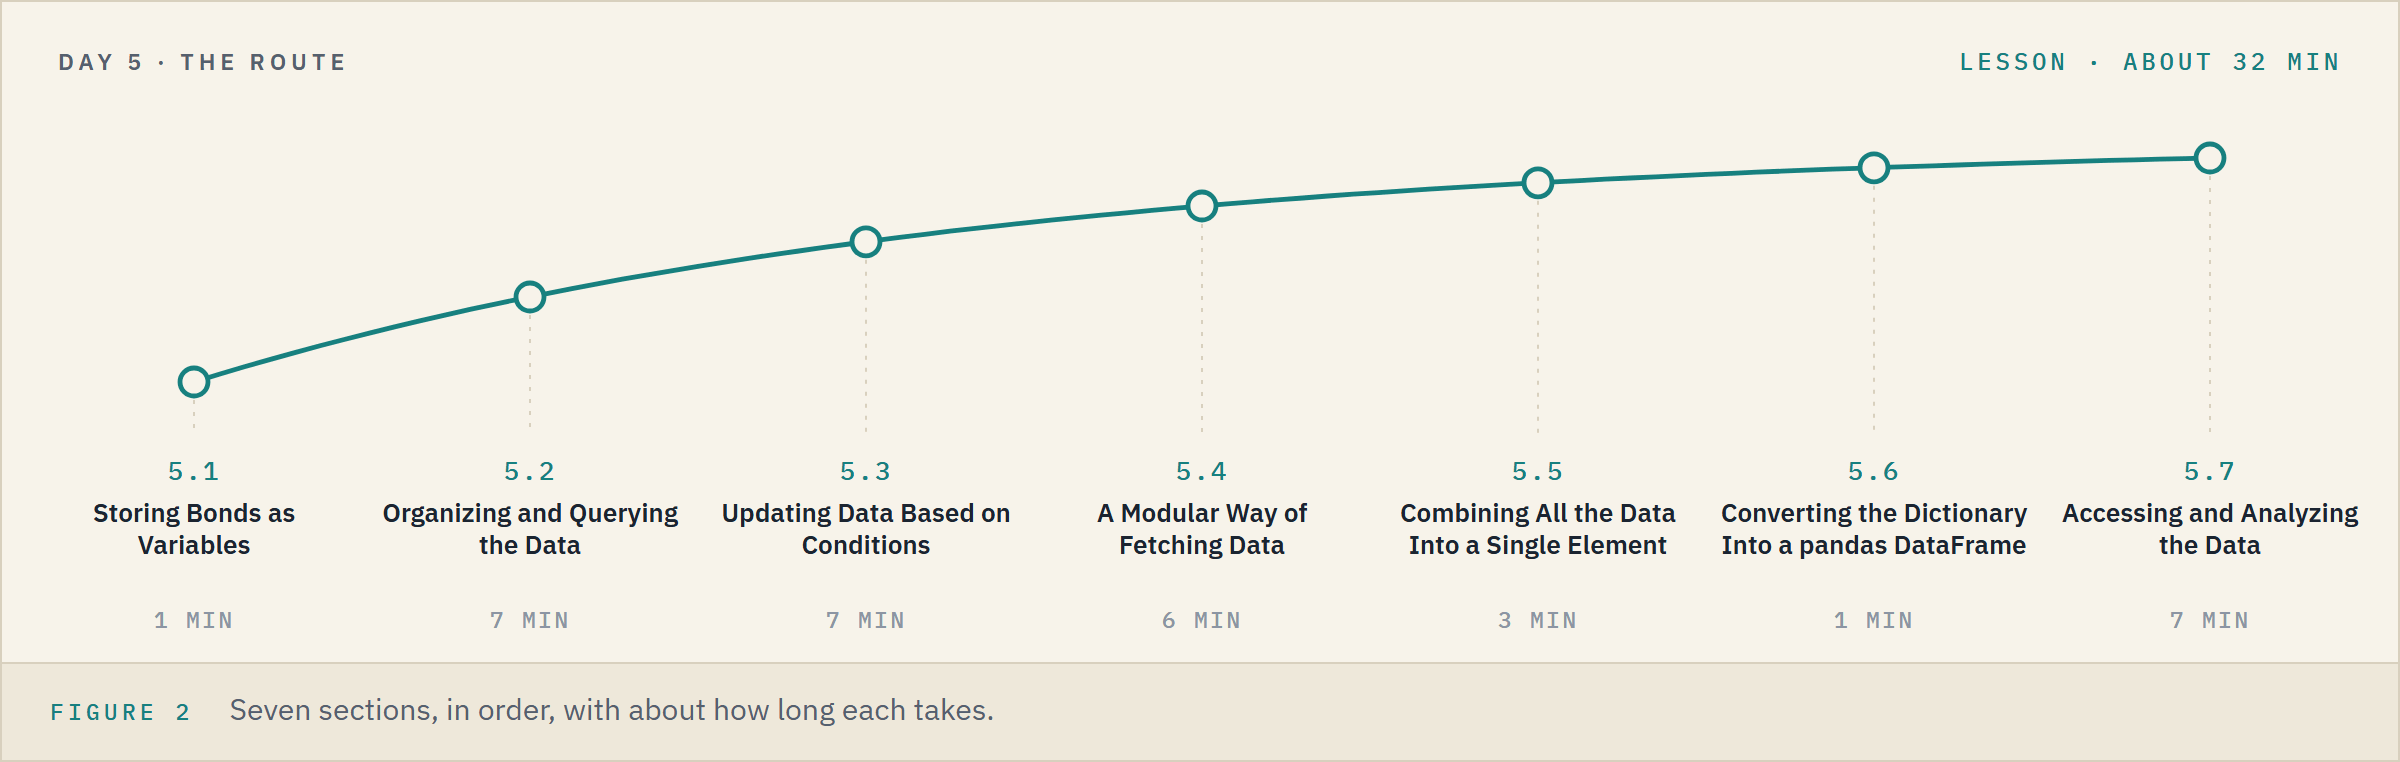

**Time.** About 32 minutes for the lesson, then about 18 for the six exercises.

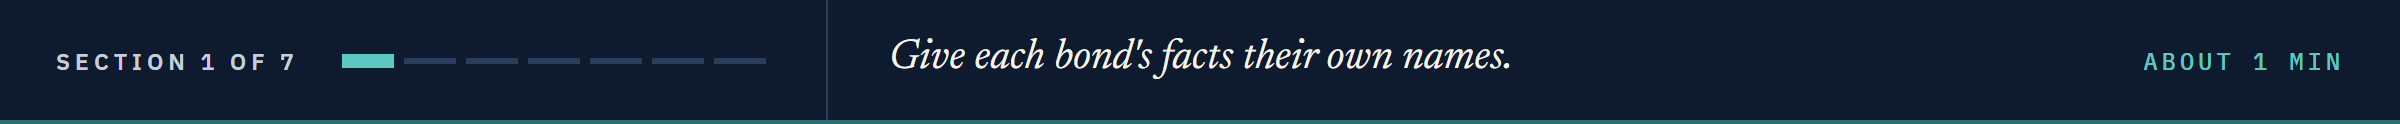

## 5.1 Storing Bonds as Variables

### One Variable per Ticker

Q. Store each ticker in a variable of its own.

In [1]:
# one variable per ticker: ticker1 is a legal name, 1ticker is not (Part 1)
ticker1 = 'QVNE'
ticker2 = 'DNMR'
ticker3 = 'PLWK'
ticker4 = 'HLVF'
ticker5 = 'OSTV'
ticker6 = 'VYRH'
print(ticker1, ticker2, ticker3, ticker4, ticker5, ticker6)

QVNE DNMR PLWK HLVF OSTV VYRH


Six names for one column, and five more columns to come.
A book of 200 bonds would need over a thousand names.

**One variable per value does not scale. Store each column as a list.**

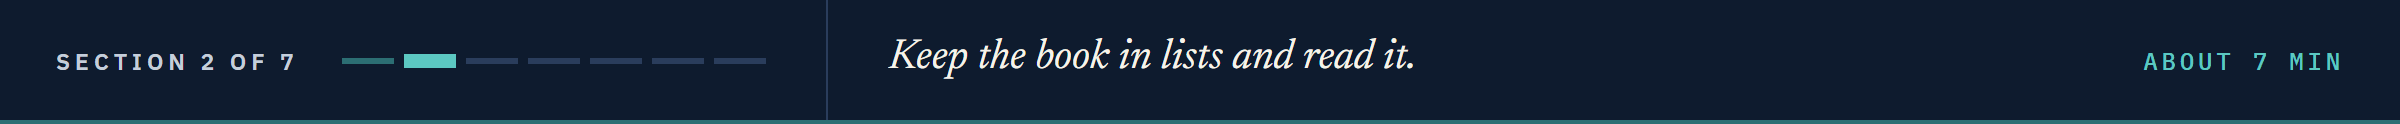

## 5.2 Organizing and Querying the Data

### Six Lists From the Email

Q. Store each column as a list, as in Part 1.

Q. Print every list, and check it against the email.

In [2]:
# one list per column, the bonds in the email's order
ticker_list = ['QVNE', 'DNMR', 'PLWK', 'HLVF', 'OSTV', 'VYRH']
sector_list = ['Energy', 'Transportation', 'Materials', 'Consumer', 'Telecom', 'Health Care']
score_list = [9, 11, 7, 14, 10, 12]
coupon_list = [5.25, 6.125, 4.75, 7.5, 5.75, 6.75]
price_list = [98.5, 103.25, 95.0, 101.0, 99.0, 102.5]
face_list = [1500000, 500000, 750000, 250000, 1000000, 400000]

In [3]:
# print every list, to check it against the email
print('Tickers:', ticker_list)
print('Sectors:', sector_list)
print('Scores:', score_list)
print('Coupons:', coupon_list)
print('Prices:', price_list)
print('Face held:', face_list)

Tickers: ['QVNE', 'DNMR', 'PLWK', 'HLVF', 'OSTV', 'VYRH']
Sectors: ['Energy', 'Transportation', 'Materials', 'Consumer', 'Telecom', 'Health Care']
Scores: [9, 11, 7, 14, 10, 12]
Coupons: [5.25, 6.125, 4.75, 7.5, 5.75, 6.75]
Prices: [98.5, 103.25, 95.0, 101.0, 99.0, 102.5]
Face held: [1500000, 500000, 750000, 250000, 1000000, 400000]


**Typed by hand, so check it before using it.**

### Tie the Lists to the Email

Q. Is there one face amount per ticker, and do the faces add up to the email's 4,400,000?

In [4]:
# one face amount for each ticker
assert len(face_list) == len(ticker_list), 'the face amounts and tickers do not match'
# the total face must tie to the email
total_face_before = sum(face_list)
assert total_face_before == 4400000, 'the face does not tie to the email'
print(f'{len(ticker_list)} bonds with a total face of {total_face_before:,}')

6 bonds with a total face of 4,400,000


Both `assert` lines stayed silent, so both were true (Day 3's rule).

**Excel side by side.** The check cell `=IF(SUM(H2:H7)=4400000,"OK","CHECK")` shows OK, and `=COUNTA(A2:A7)=COUNT(H2:H7)` shows TRUE.
A check cell calculates on; an `assert` stops the run.

**The lists tie to the email. Now fetch one bond.**

### Find a Bond, Then Read Its Row

The six lists share one order, so a bond sits at the same position in every list.
`index()`, in Day 3's `dir()` list, returns a value's position.

Q. Where is DNMR in the list of tickers?

Q. Get every detail of DNMR.

In [5]:
# DNMR's position in the list of tickers
pos = ticker_list.index('DNMR')
print(pos)

1


In [6]:
# the same position in every list
print(ticker_list[pos])
print(sector_list[pos])
print(score_list[pos])
print(coupon_list[pos])
print(price_list[pos])
print(face_list[pos])

DNMR
Transportation
11
6.125
103.25
500000


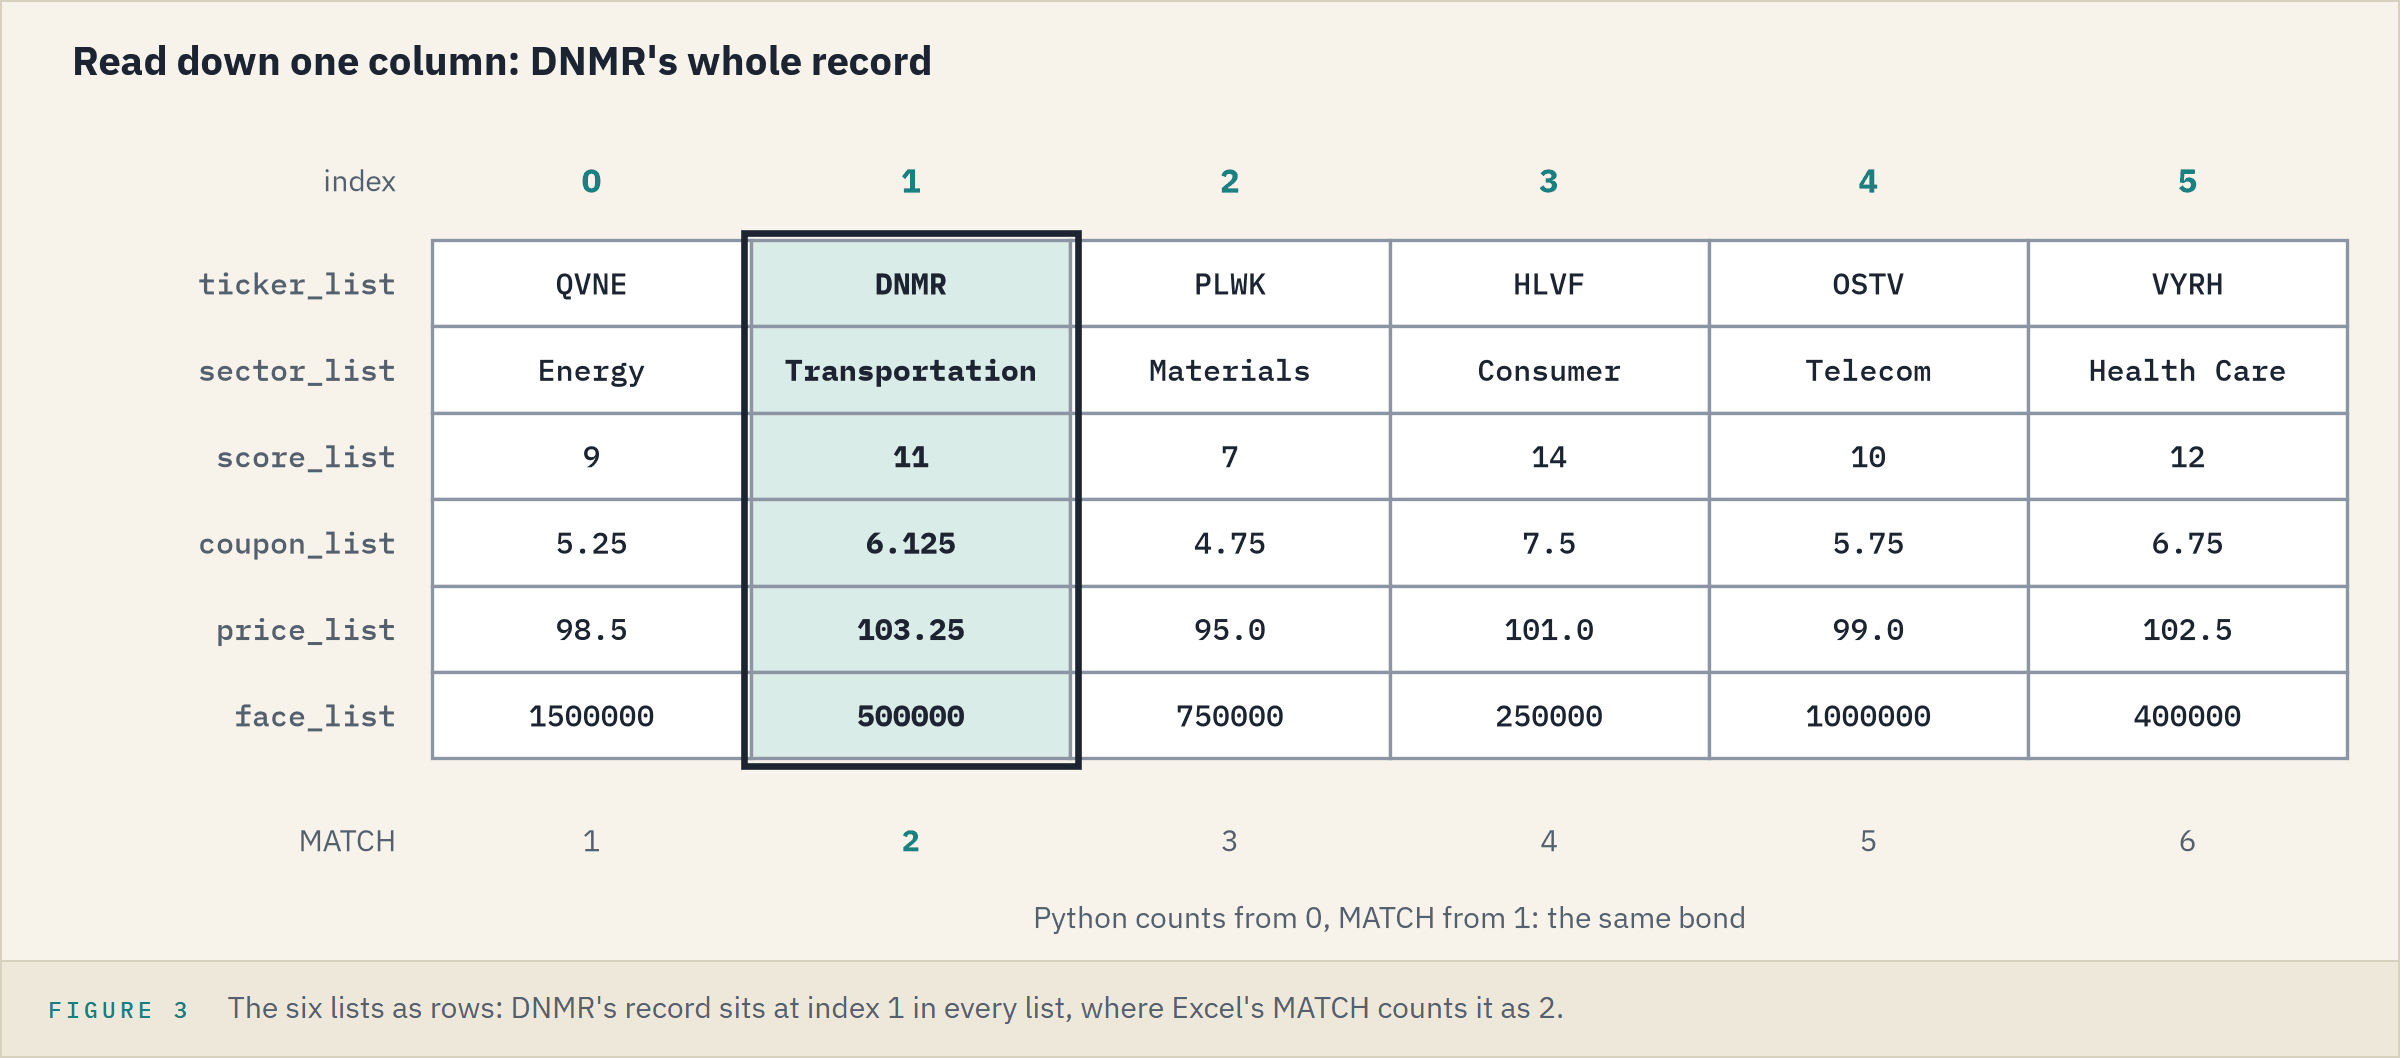

**Excel side by side.** `=MATCH("DNMR",A2:A7,0)` finds the position and returns 2; `=INDEX(F2:F7,2)` reads the coupon there, 6.125, as `coupon_list[pos]` does.

**A full record for any bond. Then news arrives.**

### A Downgrade

OSTV is downgraded one notch, from BBB- to BB+: its score moves from 10 to 11.

Q. Update the record.

In [7]:
# find OSTV, then store the new score at its position
pos = ticker_list.index('OSTV')
score_list[pos] = 11
print(score_list)

[9, 11, 7, 14, 11, 12]


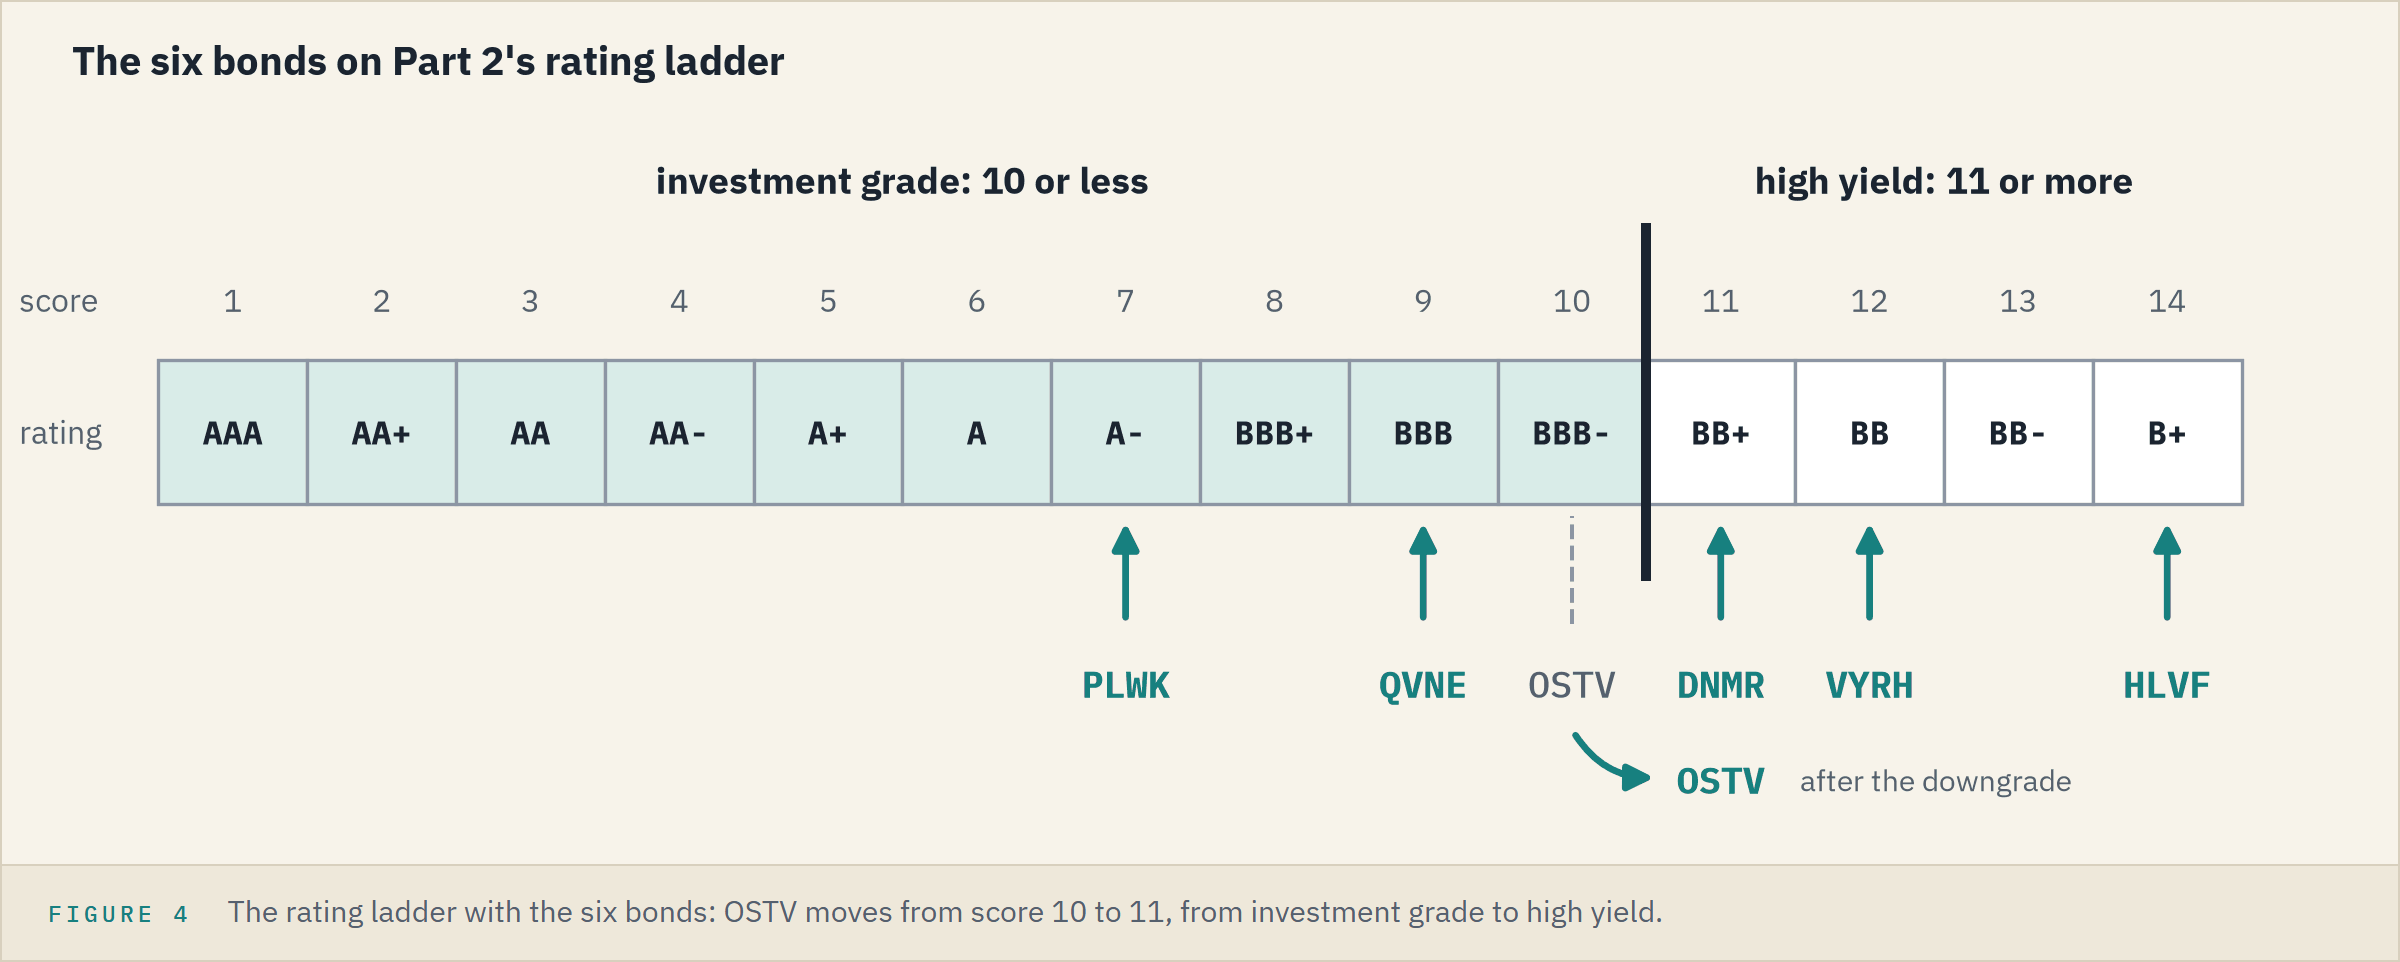

**OSTV has crossed from investment grade to high yield.**

### A List or a Tuple

**Predict 1**

From here on, a Predict shows code: decide what it will do before you run it.

Q. Each bond as one record: `bond_a` in square brackets, `bond_b` in round. Both are marked up a quarter point. What happens?

A) An error on the first update.
B) An error on the second update.
C) No error: both prices change.

In [8]:
# one record per bond: ticker, score, price
bond_a = ['QVNE', 9, 98.5]
bond_b = ('DNMR', 11, 103.25)
# both marked up a quarter point
bond_a[2] = 98.75
print(bond_a)
bond_b[2] = 103.5
print(bond_b)

['QVNE', 9, 98.75]


TypeError: 'tuple' object does not support item assignment

B: the list took its new price, and the tuple raised Part 1's `TypeError`, because a tuple cannot change.

**Data that must be updated cannot go in a tuple.**

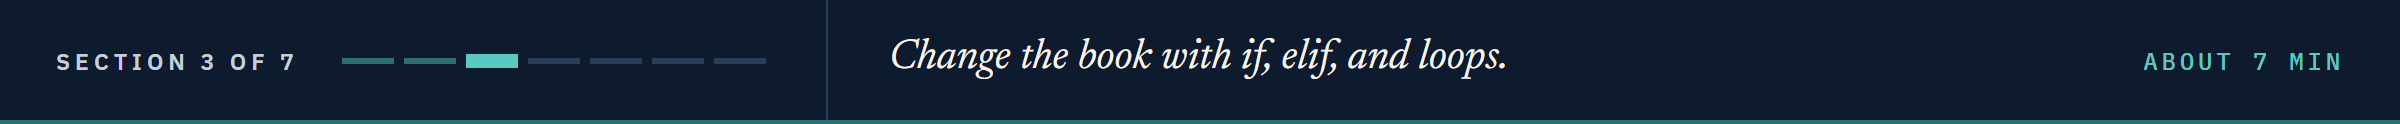

## 5.3 Updating Data Based on Conditions

### A Correction for High Yield

The pricing service writes: its high yield prices were half a point too high; investment grade was right.

Q. Keep a copy of the email's prices.

Q. Correct the first two bonds by hand, with Part 2's `if` and `else`.

In [9]:
# a separate copy of the email's prices, as in Day 3, kept for later
email_price_list = price_list.copy()

In [10]:
# QVNE, at index 0: half a point off only if high yield
if score_list[0] >= 11:
    price_list[0] = price_list[0] - 0.5
else:
    print('QVNE unchanged')
# DNMR, at index 1
if score_list[1] >= 11:
    price_list[1] = price_list[1] - 0.5
else:
    print('DNMR unchanged')
print(price_list)

QVNE unchanged
[98.5, 102.75, 95.0, 101.0, 99.0, 102.5]


**One block per bond: tedious for six, hopeless for 200.**

### Every Bond in One Loop

`enumerate()` (Part 2) hands the loop each bond's index, from 0: the position to change.
Others' code often uses `range(len(score_list))` instead.

Q. Put the email's prices back, then correct every bond in one loop.

In [11]:
# start again from the email's prices
price_list = email_price_list.copy()
# i is the bond's index, score its rating score
for i, score in enumerate(score_list):
    if score >= 11:
        price_list[i] = price_list[i] - 0.5
        print('Corrected', ticker_list[i])
print(price_list)

Corrected DNMR
Corrected HLVF
Corrected OSTV
Corrected VYRH
[98.5, 102.75, 95.0, 100.5, 98.5, 102.0]


OSTV is corrected because of its downgrade.

**Excel side by side.** With E6 updated to 11, the correction goes in a new column I: `=IF(E2>=11,G2-0.5,G2)`, filled down.
The loop changes the prices where they sit.

**The same lines would correct 200 bonds. Now ask the book questions.**

### Count by a Condition

Q. How many bonds are investment grade?

Q. How many trade above par?

Q. How many are investment grade, and how many high yield, in one loop?

In [12]:
# a counter that goes up by one for each score of 10 or lower
count = 0
# no index is needed to read, so loop over the list itself
for score in score_list:
    if score <= 10:
        count += 1
print('Investment grade bonds:', count)

Investment grade bonds: 2


In [13]:
# the same pattern, on the corrected prices
above_par = 0
for price in price_list:
    if price > 100:
        above_par += 1
print('Bonds above par:', above_par)

Bonds above par: 3


In [14]:
# two counters: else catches every score above 10
investment_grade = 0
high_yield = 0
for score in score_list:
    if score <= 10:
        investment_grade += 1
    else:
        high_yield += 1
print('Investment grade:', investment_grade)
print('High yield:', high_yield)

Investment grade: 2
High yield: 4


**Excel side by side.** `=COUNTIF(E2:E7,"<=10")` returns 2 and `=COUNTIF(I2:I7,">100")` returns 3.
A loop can also do more to each matching bond while it is there.

**Two tests at once need a joining word.**

### Both Tests or Either

**Predict 2**

Q. Count the bonds that are high yield and also above par: `and` or `or` between the tests, and what count? The cell tries both.

In [15]:
# two counters, one for each joining word
count_and = 0
count_or = 0
for score, price in zip(score_list, price_list):
    if score >= 11 and price > 100:
        count_and += 1
    if score >= 11 or price > 100:
        count_or += 1
print('With and:', count_and)
print('With or:', count_or)

With and: 3
With or: 4


`and` is right, with 3: DNMR, HLVF, and VYRH.
`or` counts 4, letting in OSTV, high yield but below par (Part 2's Compare and Combine).

**Excel side by side.** `=COUNTIFS(E2:E7,">=11",I2:I7,">100")` counts the rows that pass both tests: 3.

**`and` needs both tests; OSTV passes only one.**

### Trades Waiting to Settle

**Predict 3**

Q. Three trades wait to settle. How many times does `Settling a trade` print, and when does the last line run?

In [16]:
# three trades, settled one at a time
trades_to_settle = 3
while trades_to_settle > 0:
    print('Settling a trade')
    trades_to_settle = trades_to_settle - 1
print('All trades settled')

Settling a trade
Settling a trade
Settling a trade
All trades settled


Three times: each pass takes one off, and the `while` (Part 2) stops at 0.
The last line is not indented, so it runs once, after the loop.

**The indent decides what repeats.**

### Everything About One Bond

Q. Print everything about HLVF.

In [17]:
# find HLVF by its ticker, then read every list at its index
for i, ticker in enumerate(ticker_list):
    if ticker == 'HLVF':
        print(f'Ticker: {ticker}')
        print(f'Sector: {sector_list[i]}')
        print(f'Score: {score_list[i]}')
        print(f'Coupon: {coupon_list[i]:.3f} percent')
        print(f'Price: {price_list[i]:.2f}')
        print(f'Face held: {face_list[i]:,}')

Ticker: HLVF
Sector: Consumer
Score: 14
Coupon: 7.500 percent
Price: 100.50
Face held: 250,000


Part 1's format codes give 100.50 and 250,000.

**It works for HLVF; another bond means copying it.**

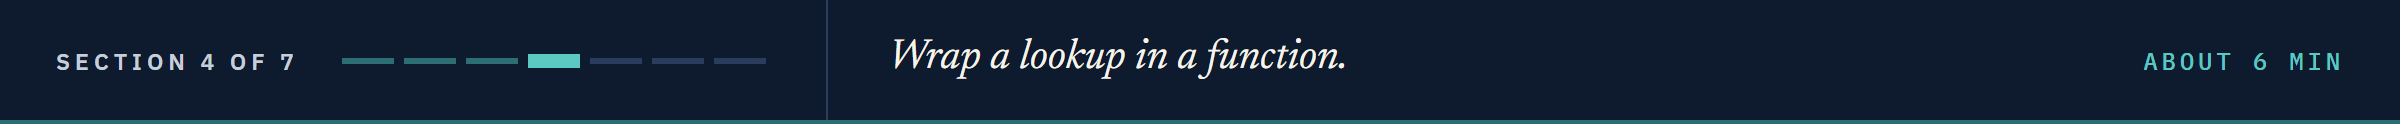

## 5.4 A Modular Way of Fetching Data

### A Function for Any Bond

Copied code spreads mistakes: a fix in one copy misses the others.

Q. Write a function, as in Part 2, that prints everything about any bond.

Q. Look up QVNE and VYRH.

In [18]:
def bond_info(ticker):
    """Print everything the desk holds on one bond."""
    # find the bond's position, then read every list there
    pos = ticker_list.index(ticker)
    print(f'Ticker: {ticker_list[pos]}')
    print(f'Sector: {sector_list[pos]}')
    print(f'Score: {score_list[pos]}')
    print(f'Coupon: {coupon_list[pos]:.3f} percent')
    print(f'Price: {price_list[pos]:.2f}')
    print(f'Face held: {face_list[pos]:,}')
    # a line of dashes between bonds: text times a number repeats (Day 3)
    print('-' * 30)

In [19]:
# one line per lookup
bond_info('QVNE')
bond_info('VYRH')

Ticker: QVNE
Sector: Energy
Score: 9
Coupon: 5.250 percent
Price: 98.50
Face held: 1,500,000
------------------------------
Ticker: VYRH
Sector: Health Care
Score: 12
Coupon: 6.750 percent
Price: 102.00
Face held: 400,000
------------------------------


If the layout ever changes, it changes in one place.

**Any bond the desk holds, in one line. Now one it does not hold.**

### A Ticker Not Held

Q. Look up ABCD, a ticker the desk does not hold.

In [20]:
# ABCD is not in the book: this cell is meant to fail
bond_info('ABCD')

ValueError: 'ABCD' is not in list

Read the last line first, as on Day 3: `index()` raises a `ValueError` for a value the list does not hold.

**The lower arrow is where it failed; the upper, the call that asked for ABCD.**

### Print or Return

**Predict 4**

Q. `coupon_printed` prints QVNE's coupon and `coupon_returned` returns it. Each result is stored, then printed. What does each cell show?

In [21]:
# Function 1
def coupon_printed(ticker):
    pos = ticker_list.index(ticker)
    print(coupon_list[pos])


result = coupon_printed('QVNE')
print(result)

5.25
None


In [22]:
# Function 2
def coupon_returned(ticker):
    pos = ticker_list.index(ticker)
    return coupon_list[pos]


result = coupon_returned('QVNE')
print(result)

5.25


The first shows 5.25, then `None`: it printed the coupon and handed nothing back (Part 2).
The second shows 5.25 once: `result` holds the number, ready to use.

**Use `return` whenever the answer is needed afterwards.**

### Which Test Comes First

**Predict 5**

Q. Two analysts write a rating bucket with the same tests in a different order. PLWK scores 7. What does each function return?

In [23]:
# Function 1
def bucket_one(score):
    if score <= 7:
        label = 'A or better'
    elif score <= 10:
        label = 'BBB'
    else:
        label = 'High yield'
    return label


print('Function 1:', bucket_one(7))

Function 1: A or better


In [24]:
# Function 2
def bucket_two(score):
    if score <= 10:
        label = 'BBB'
    elif score <= 7:
        label = 'A or better'
    else:
        label = 'High yield'
    return label


print('Function 2:', bucket_two(7))

Function 2: BBB


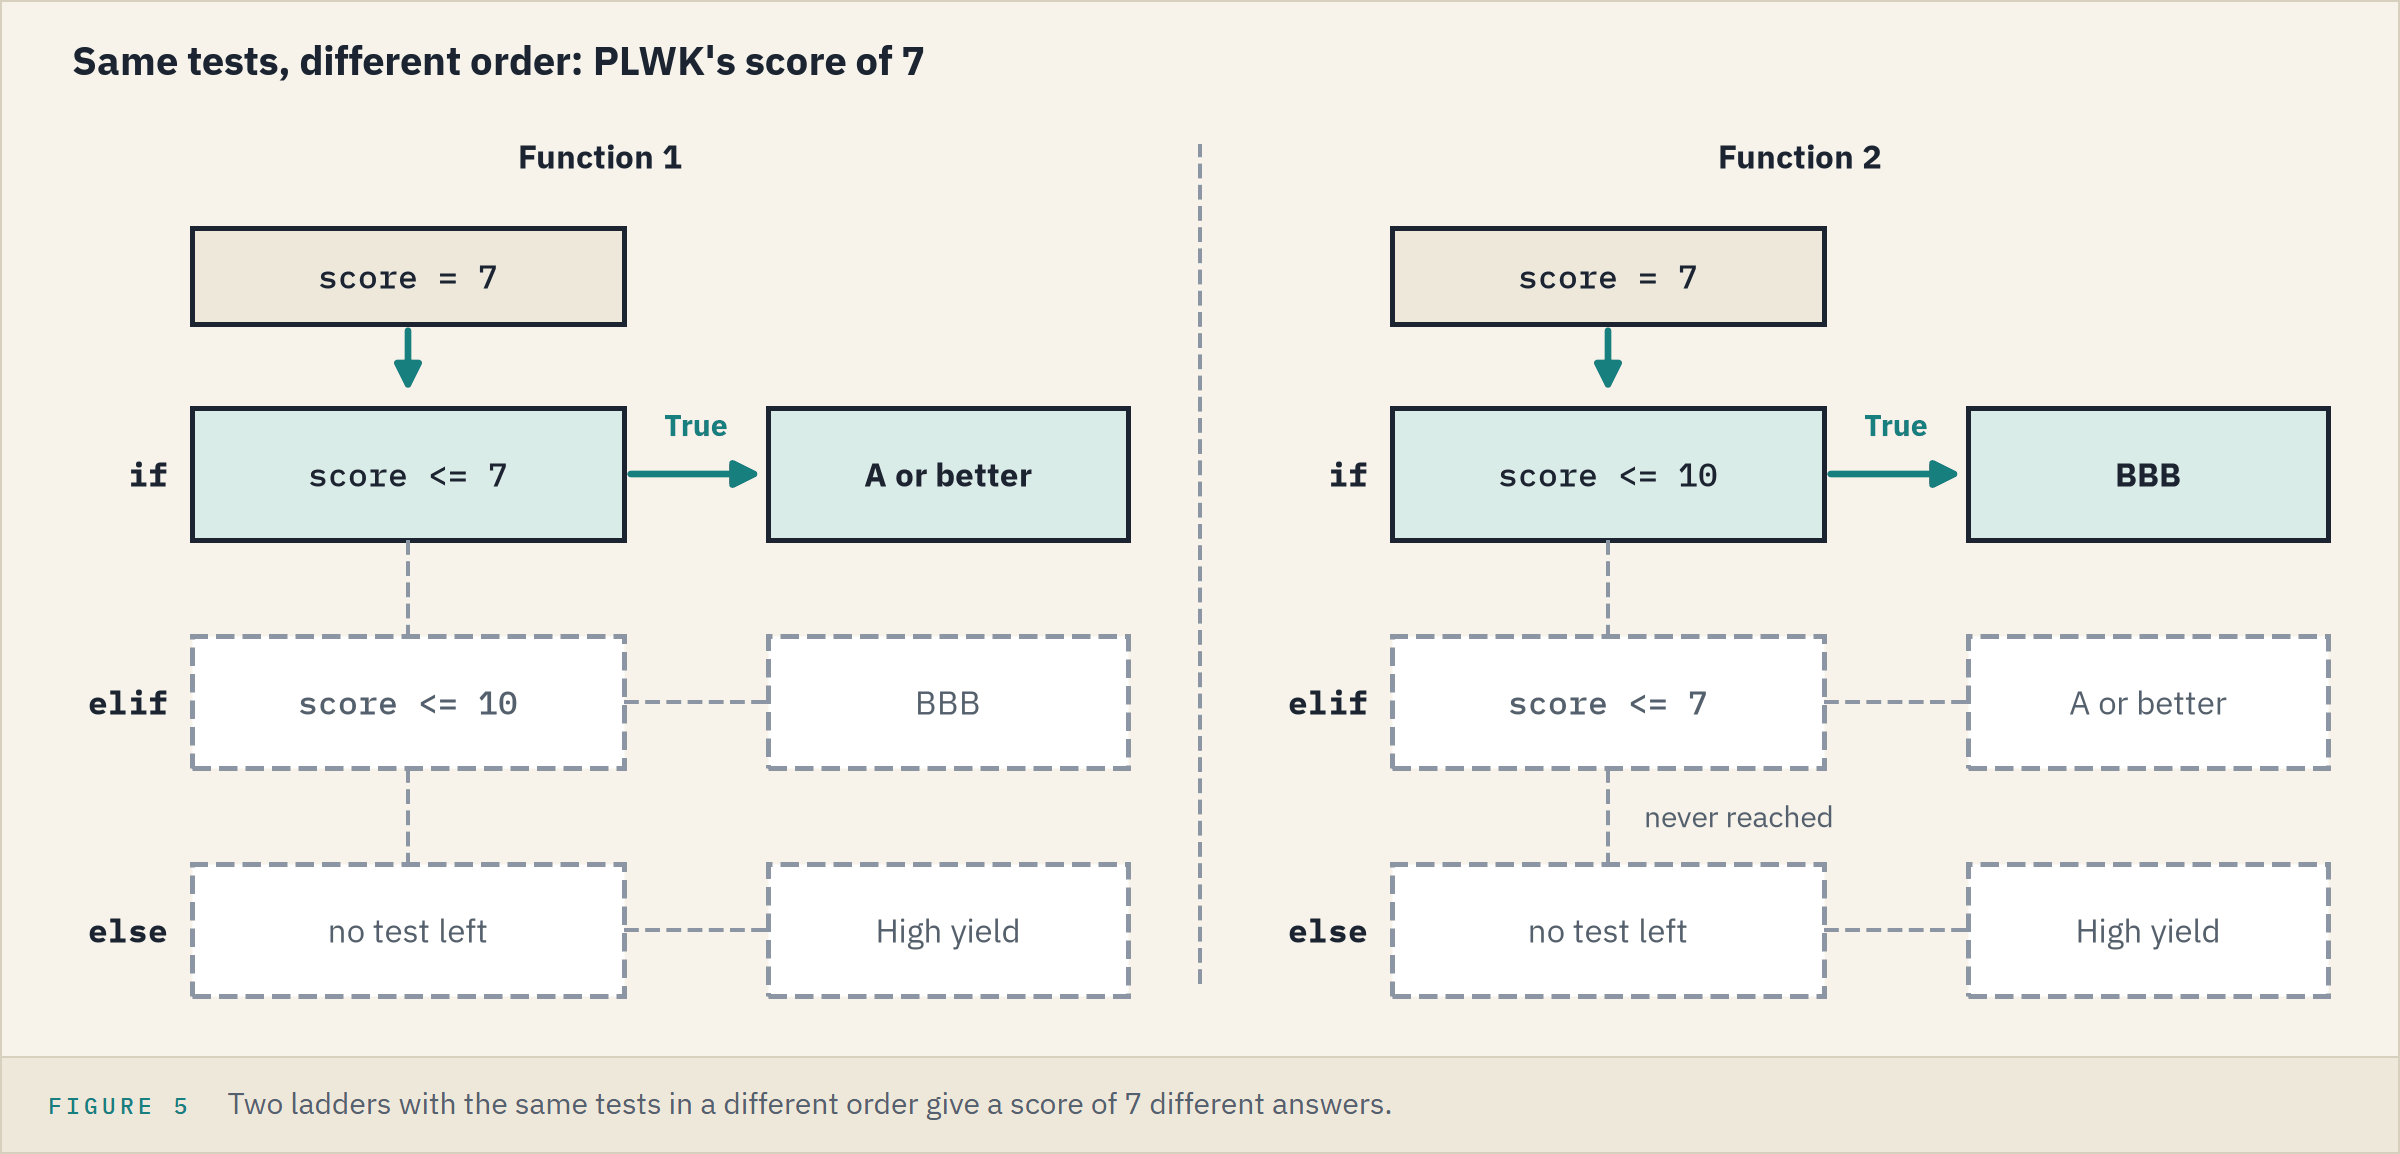

Function 2's 'BBB' is wrong for an A- bond.

**Excel side by side.** `IFS` also stops at the first true test: `=IFS(E4<=10,"BBB",E4<=7,"A or better",TRUE,"High yield")` returns BBB for PLWK, and swapping the first two tests returns A or better.
`IFS` needs Excel 2019 or later, or Microsoft 365.

**When conditions overlap, put the narrowest first.**

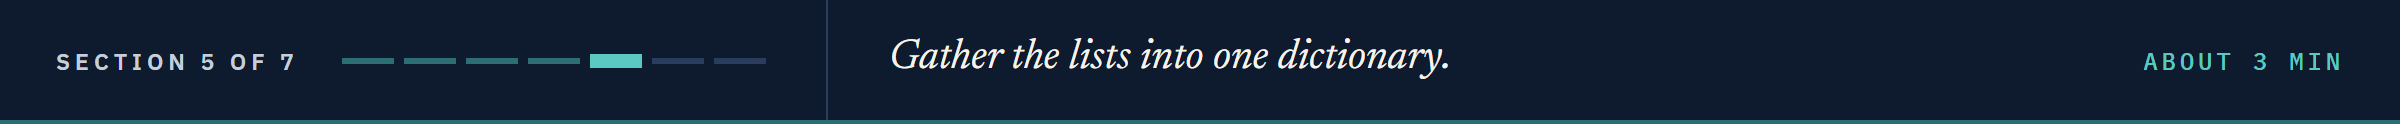

## 5.5 Combining All the Data Into a Single Element

### Six Lists, One Dictionary

Six separate names: a function or a colleague has to be handed all six, in the right order.

Q. Put the six lists in one dictionary, column names as keys, as Part 1 did for four.

In [25]:
# each key is a column name, and each value is that column's list
portfolio = {
    'Ticker': ticker_list,
    'Sector': sector_list,
    'Score': score_list,
    'Coupon': coupon_list,
    'Price': price_list,
    'Face': face_list,
}
portfolio

{'Ticker': ['QVNE', 'DNMR', 'PLWK', 'HLVF', 'OSTV', 'VYRH'],
 'Sector': ['Energy',
  'Transportation',
  'Materials',
  'Consumer',
  'Telecom',
  'Health Care'],
 'Score': [9, 11, 7, 14, 11, 12],
 'Coupon': [5.25, 6.125, 4.75, 7.5, 5.75, 6.75],
 'Price': [98.5, 102.75, 95.0, 100.5, 98.5, 102.0],
 'Face': [1500000, 500000, 750000, 250000, 1000000, 400000]}

**One name now holds the book.**

### A Column, Then One Bond

Q. Get the tickers, then the third one.

Q. Print every column's value for HLVF, at index 3.

In [26]:
# a column by its key, then one item by its index
print(portfolio['Ticker'])
print(portfolio['Ticker'][2])

['QVNE', 'DNMR', 'PLWK', 'HLVF', 'OSTV', 'VYRH']
PLWK


In [27]:
# items() hands over each key with its list (Part 2)
for key, value in portfolio.items():
    print(key, value[3])

Ticker HLVF
Sector Consumer
Score 14
Coupon 7.5
Price 100.5
Face 250000


**Here the columns are the keys. The bonds could be.**

### Tickers as Keys

**Predict 6**

Q. Now each key is a ticker, and its value lists that bond's score, coupon, and price. What does the loop print?

In [28]:
# each key a ticker; each value that bond's score, coupon, price
by_ticker = {
    'QVNE': [9, 5.25, 98.5],
    'DNMR': [11, 6.125, 102.75],
    'PLWK': [7, 4.75, 95.0],
}
for key, value in by_ticker.items():
    print(key, value[1])

QVNE 5.25
DNMR 6.125
PLWK 4.75


The key is the ticker, and `value[1]`, the second item, is the coupon.
Part 1's columns or rows: here each key is a row.

Either way, every question still needs a loop written by hand.
A library is tested code someone else wrote (Day 0).

**A pandas table answers the same questions in one line.**

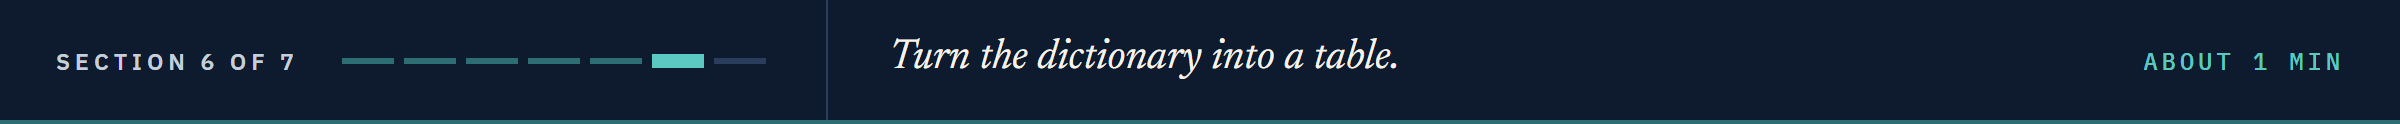

## 5.6 Converting the Dictionary Into a pandas DataFrame

### The Book as a Table

Q. Turn `portfolio` into a DataFrame, as Part 1 did, and show it.

In [29]:
# pandas, imported as in Day 0
import pandas as pd
# keys become column names and each list a column; df is the usual short name
df = pd.DataFrame(portfolio)
df

,Ticker,Sector,Score,Coupon,Price,Face
0,QVNE,Energy,9,5.250,98.50,1500000
1,DNMR,Transportation,11,6.125,102.75,500000
2,PLWK,Materials,7,4.750,95.00,750000
3,HLVF,Consumer,14,7.500,100.50,250000
4,OSTV,Telecom,11,5.750,98.50,1000000
5,VYRH,Health Care,12,6.750,102.00,400000


**Excel side by side.** A DataFrame is a worksheet: named columns, one bond per row.
Here every step that made it is written down, and reruns tomorrow on a new email.

**The email is now a table. Ask it questions.**

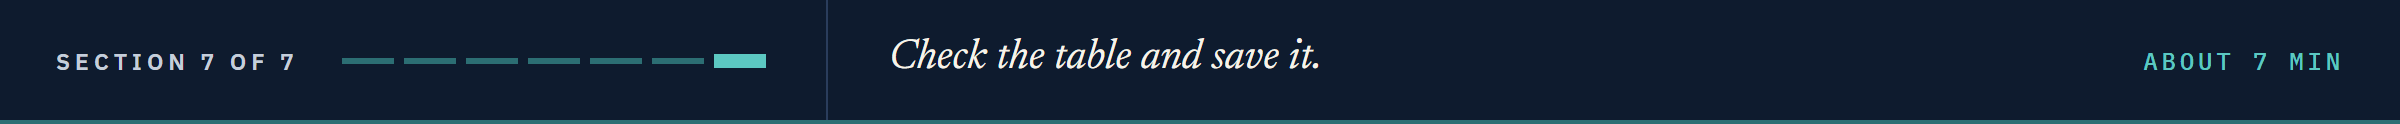

## 5.7 Accessing and Analyzing the Data

### First and Last Rows

Q. Show the first three rows, then the last three.

In [30]:
# head(3): the first 3 rows; with nothing in the brackets, the first 5
df.head(3)

,Ticker,Sector,Score,Coupon,Price,Face
0,QVNE,Energy,9,5.250,98.50,1500000
1,DNMR,Transportation,11,6.125,102.75,500000
2,PLWK,Materials,7,4.750,95.00,750000


In [31]:
# tail(3): the last 3 rows; with nothing in the brackets, the last 5
df.tail(3)

,Ticker,Sector,Score,Coupon,Price,Face
3,HLVF,Consumer,14,7.50,100.5,250000
4,OSTV,Telecom,11,5.75,98.5,1000000
5,VYRH,Health Care,12,6.75,102.0,400000


On 200 bonds: both ends, without printing every row.

### Size and Types

Q. How many rows and columns does the table have?

Q. What type is each column, and is anything missing?

In [32]:
# shape: the number of rows, then the number of columns
print(df.shape)
# info(): each column's name, how many values it holds, and its type
df.info()

(6, 6)
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Ticker  6 non-null      str    
 1   Sector  6 non-null      str    
 2   Score   6 non-null      int64  
 3   Coupon  6 non-null      float64
 4   Price   6 non-null      float64
 5   Face    6 non-null      int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 499.0 bytes


The first line names its class: a DataFrame is an object, as on Day 4, so `head()` and `info()` are methods, with brackets, and `shape` an attribute, without.
`int64` is whole numbers, `float64` decimals, and `str` text (`object` in older pandas).

**Nothing is missing, so every number column can be summarized.**

### Every Column in One Line

Q. Summarize every number column.

In [33]:
# describe() summarizes every number column
df.describe()

,Score,Coupon,Price,Face
count,6.000000,6.000000,6.000000,6.000000e+00
mean,10.666667,6.020833,99.541667,7.333333e+05
std,2.422120,1.001301,2.830268,4.600725e+05
min,7.000000,4.750000,95.000000,2.500000e+05
25%,9.500000,5.375000,98.500000,4.250000e+05
50%,11.000000,5.937500,99.500000,6.250000e+05
75%,11.750000,6.593750,101.625000,9.375000e+05
max,14.000000,7.500000,102.750000,1.500000e+06


**Excel side by side.** Each row of `describe()`, on the corrected prices in I2:I7:

<table align="left">
<tr><th align="left">Row</th><th align="left">Means</th><th align="left">Excel</th></tr>
<tr><td align="left">count</td><td align="left">how many values</td><td align="left"><code>=COUNT(I2:I7)</code></td></tr>
<tr><td align="left">mean</td><td align="left">the average</td><td align="left"><code>=AVERAGE(I2:I7)</code></td></tr>
<tr><td align="left">std</td><td align="left">standard deviation: how spread out the values are</td><td align="left"><code>=STDEV.S(I2:I7)</code></td></tr>
<tr><td align="left">min, max</td><td align="left">the two ends</td><td align="left"><code>=MIN(I2:I7)</code>, <code>=MAX(I2:I7)</code></td></tr>
<tr><td align="left">25%, 75%</td><td align="left">a quarter, and three quarters, of the way up</td><td align="left"><code>=QUARTILE.INC(I2:I7,1)</code>, <code>=QUARTILE.INC(I2:I7,3)</code></td></tr>
<tr><td align="left">50%</td><td align="left">the median, the middle value</td><td align="left"><code>=MEDIAN(I2:I7)</code></td></tr>
</table>
<br clear="left">

One line, 32 numbers: eight for each of the four number columns.
Face's `7.333333e+05` is about 733,333: times 10 to the power 5, as `e+04` was in Part 1; Excel's Scientific format shows 7.33E+05.
The median price, 99.5, sits halfway between the two middle prices, 98.5 and 100.5.
The median score is 11: after the downgrade, the middle of the book is high yield.

**The numbers summarize; a chart shows each bond.**

### What the Correction Did

Q. Draw each bond's email price beside its corrected price.

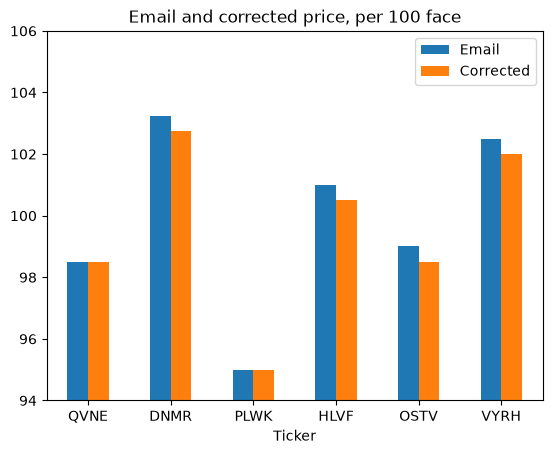

In [34]:
# the two price lists side by side, by ticker
prices = pd.DataFrame({'Ticker': ticker_list, 'Email': email_price_list,
                       'Corrected': price_list})
# with no y=, plot.bar draws every number column, as on Day 4
# ylim= sets the side axis from 94 to 106, so half a point shows
chart = prices.plot.bar(x='Ticker', rot=0, ylim=(94, 106),
                        title='Email and corrected price, per 100 face')

**Four bars drop half a point; QVNE and PLWK, investment grade, do not.**

### Price Against Par

Q. How far is each bond from par, and which are high yield?

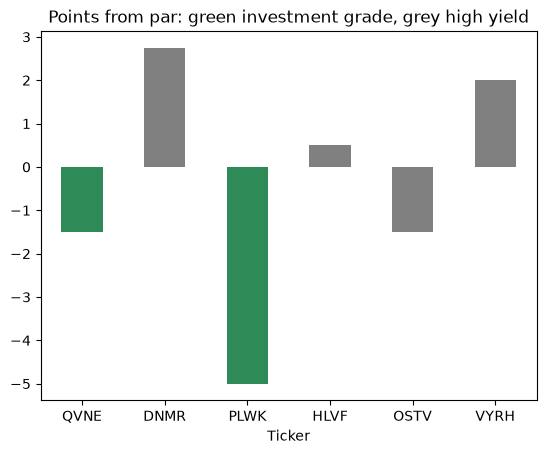

In [35]:
# points from par for each bond, by a comprehension (Part 2)
from_par = [price - 100 for price in price_list]
# one colour per bond, chosen by its score: green investment grade, grey high yield
colors = ['seagreen' if score <= 10 else 'grey' for score in score_list]
table = pd.DataFrame({'Ticker': ticker_list, 'From par': from_par})
# color= takes one colour per bar; the title explains them, so no legend
chart = table.plot.bar(x='Ticker', y='From par', rot=0, color=colors, legend=False,
                       title='Points from par: green investment grade, grey high yield')

**Excel side by side.** Put `=I2-100` in a new column, fill it down, then Insert, Column Chart: the same bars.

**Three above par, three below; four of six high yield.**

### Tie the Table, Then Hand It On

Q. Does the table's total face still tie to the email?

Q. Write the table to a CSV file, read it back, and tie it again.

Q. Then leave the folder as you found it, as Day 2 did.

In [36]:
# a column by its name, then sum() adds it up
total_face_after = df['Face'].sum()
# the table must hold what the lists held: every bond, and the same face
assert len(df) == len(ticker_list), 'a bond went missing'
assert total_face_after == total_face_before, 'the face no longer ties'
print(f'Total face held: {total_face_after:,}')

Total face held: 4,400,000


In [37]:
# to_csv() writes the table to a file; index=False leaves out the row numbers 0 to 5
df.to_csv('handover.csv', index=False)
# read it back with Day 2's read_csv(), and tie it to the email once more
handover = pd.read_csv('handover.csv')
assert handover['Face'].sum() == total_face_before, 'the file does not tie to the email'
print(len(handover), 'bonds read back from handover.csv')

6 bonds read back from handover.csv


In [38]:
# on a desk the file stays; here the folder goes back to the way we found it
import os
os.remove('handover.csv')
print(os.path.exists('handover.csv'))

False


No loop and no running total: `df['Face'].sum()` is `=SUM(H2:H7)`, and `.mean()`, `.min()`, and `.count()` work the same way.

**Excel side by side.** File, Save As, CSV (Comma delimited) does the job of `to_csv()`; opening the file again is `read_csv()`.

**4,400,000 in the email, the lists, the table, and the file: the book is in order.**

## Summary

The report to the desk:

<table align="left">
<tr><th align="left">The desk asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Put the book in order</td><td align="left">one pandas table: six bonds, six columns, nothing missing</td></tr>
<tr><td align="left">Tie it to the email</td><td align="left">4,400,000 face, by <code>assert</code> on the lists, the table, and the file</td></tr>
<tr><td align="left">Look up one bond</td><td align="left"><code>bond_info('QVNE')</code>: one line</td></tr>
<tr><td align="left">Update a bond</td><td align="left">OSTV's downgrade by position; the high yield correction in one loop</td></tr>
<tr><td align="left">Answer simple questions</td><td align="left">2 investment grade, 4 high yield, 3 above par</td></tr>
<tr><td align="left">Hand it on for analysis</td><td align="left"><code>df</code>, a DataFrame, and a CSV file read back with <code>read_csv()</code></td></tr>
</table>
<br clear="left">

## You Can Now

By the end of this notebook, you can:

* Look up and update any bond by its position in a list.
* Apply a change to the right bonds with a condition inside a loop.
* Count what you need, the way `COUNTIF` does.
* Turn a lookup into a function, and return the answer.
* Gather lists into a dictionary, turn it into a DataFrame, and save it as a CSV file.
* Tie a total to its source with `assert`, before and after a change.

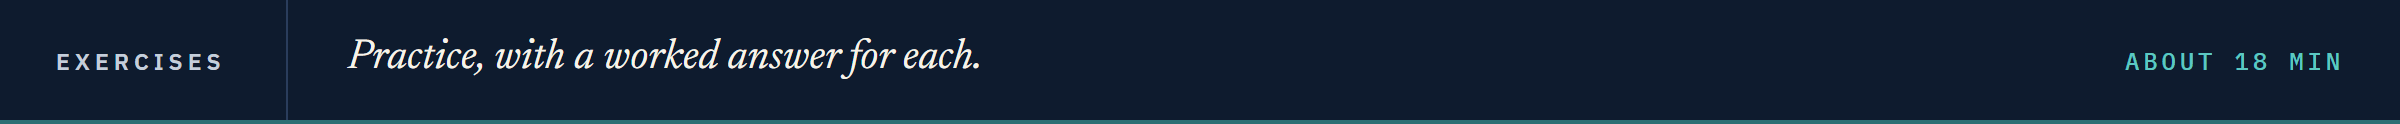

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second, smaller book has arrived the same way.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">A</td><td align="left">6</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">BBB-</td><td align="left">10</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">B</td><td align="left">15</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`, which marks your answers, and stores the second book as lists.

In [39]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second book
ticker_list = ['TRNW', 'OSMC', 'CLDB']
score_list = [6, 10, 15]
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

### Exercise 1

Q. Find OSMC's position with `index()`, then its price at that position. Store the price in **ex1_price**.

In [40]:
ex1_price = ...

In [41]:
check('Exercise 1', ex1_price, 100.0)

Exercise 1: not attempted yet


### Exercise 2

Q. With a loop and a condition, count the investment grade bonds, scores of 10 or lower. Store the count in **ex2_ig_count**.

In [42]:
ex2_ig_count = ...

In [43]:
check('Exercise 2', ex2_ig_count, 2)

Exercise 2: not attempted yet


### Exercise 3

Q. Complete **bond_cost**: take a ticker and return that position's cost at the clean price, face times price over 100, accrued interest left out. The code stores CLDB's cost in **ex3_cost**.

In [44]:
def bond_cost(ticker):
    return ...


ex3_cost = bond_cost('CLDB')

In [45]:
check('Exercise 3', ex3_cost, 522500.0)

Exercise 3: not attempted yet


### Exercise 4

Q. Put the five lists in a dictionary with the keys 'Ticker', 'Score', 'Coupon', 'Price', and 'Face', and turn it into a DataFrame. Store its shape in **ex4_shape**.

In [46]:
import pandas as pd

ex4_shape = ...

In [47]:
check('Exercise 4', ex4_shape, (3, 5))

Exercise 4: not attempted yet


### Exercise 5

Q. Complete **total_face**: take a table with a 'Face' column and return the total face held. The cell builds **second_df**; the check calls your function on the whole table and on its first two rows.

In [48]:
import pandas as pd

# the second book as a table
second_df = pd.DataFrame({
    'Ticker': ticker_list,
    'Score': score_list,
    'Coupon': coupon_list,
    'Price': price_list,
    'Face': face_list
})


def total_face(table):
    """
    Take a table with a 'Face' column
    and return the total face held.
    """
    return ...

In [49]:
check('Exercise 5 whole table', total_face(second_df), 3750000)
check('Exercise 5 first two rows', total_face(second_df.head(2)), 3250000)

Exercise 5 whole table: not attempted yet
Exercise 5 first two rows: not attempted yet


### Exercise 6: AI check

An AI assistant wrote code to total the three positions' cost at the clean price; it has one bug.

Q. Before you run it, work out the total yourself: the three costs are 1,925,000, 1,250,000, and 522,500. Then run the code. Does it agree with you?

Q. Find the bug and fix the code, so that **ex6_total_cost** holds the right answer.

In [50]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
ex6_total_cost = 0
for i in range(len(ticker_list) - 1):
    ex6_total_cost = ex6_total_cost + face_list[i] * price_list[i] / 100

print(f'The total cost is {ex6_total_cost:,.2f}')

The total cost is 3,175,000.00


In [51]:
check('Exercise 6', ex6_total_cost, 3697500.0)

Exercise 6: not yet. You have 3175000.0


## Congratulations!

You made it through Day 5, and through Week 1.
An email of six bonds is now one checked table and a file, built with the whole week, one step at a time, as the first picture showed.
A week ago you may never have opened a notebook.
Today you did a piece of work a desk needs done, and you can show every step that got you there.
Be proud of that.

This week, almost every question about a column took a loop.
Next, in Week 2, NumPy does the arithmetic on a whole column of bonds in a single line.

[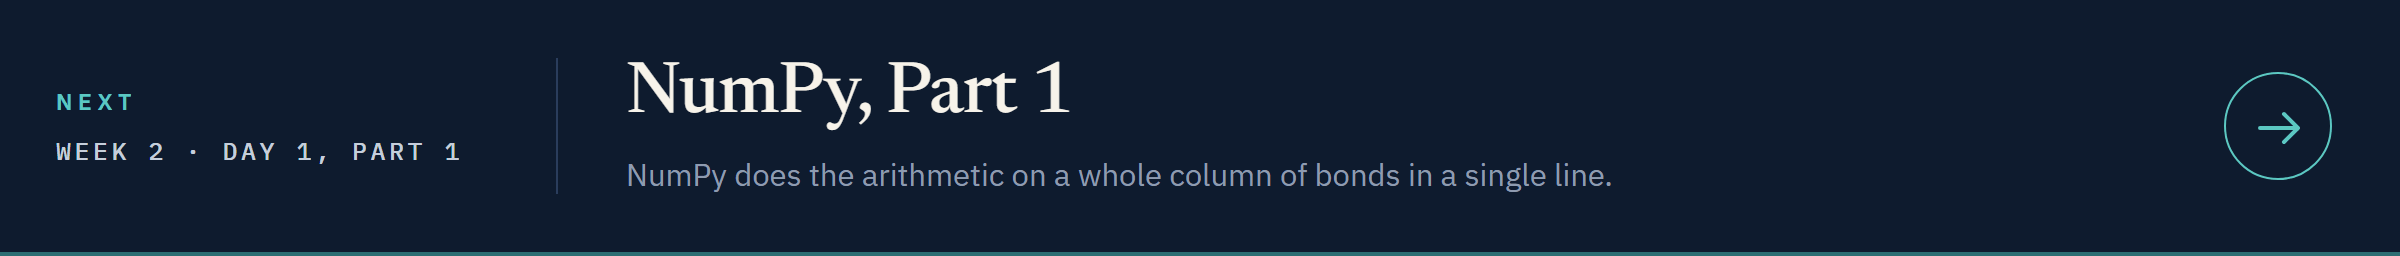](../../week2/day1/06_numpy.ipynb)

[Open Day 1, Part 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week2/day1/06_numpy.ipynb)